# Placement prediction: analysis

Goal: predict `placed` (1 = received an offer through the placement cell) for a new list of registered students.
The metric is **F1 for `placed = 1`**.

> **TL;DR**
> - **Result:** a logistic regression with a tuned threshold (0.25) scores **CV F1 ≈ 0.56** (holdout 0.58), against 0.44 for predicting "placed" for everyone. On a list of about 500 students, expect roughly **0.50–0.62**.
> - **`status_code` is target leakage and is excluded.** On its own it reproduces the label (F1 0.94). A model that uses it scores 0.92 here but **falls to 0.06–0.34 when the field isn't filled in yet**, which is worse than the trivial baseline (2.6). It is available only behind `--use-status-code`.
> - **`city_tier` is also excluded:** it adds nothing (−0.002 F1) and may stand in for family background.
> - **Simple wins:** gradient boosting, random forests, splines and interaction terms were no better. These features cap AUC at about 0.77; missed placements look like ordinary students, so what placed them isn't in the data.
> - **Caveat:** the model reproduces the department gap (it catches 86% of placed CSE students but only 37% of placed ECE students). The probabilities are calibrated, so for targeting support the cell should rank students within a department (2.9).

The notebook covers:
1. **EDA**: data quality, how each feature relates to placement, missing values, and the `status_code` column.
2. **Modelling**: model comparison (2.2–2.4), coefficients (2.5), leak stress test (2.6), uncertainty (2.7), error analysis (2.8), fairness and use (2.9), saved models and `predict.py` test (2.10–2.11).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.width", 160)
sns.set_theme(style="whitegrid")

df = pd.read_csv("data/train.csv")
print(df.shape)
df.head()

(2500, 11)


,student_id,department,city_tier,cgpa,backlogs,internship_months,coding_score,projects,workshops,status_code,placed
0,S00802,CSE,2,7.00,1.0,5,56.6,5,4,NaN,1
1,S02107,CSE,3,8.06,1.0,4,29.9,1,3,1.0,1
2,S01945,CSE,3,7.92,0.0,0,52.4,2,2,0.0,0
3,S01956,MECH,2,7.49,1.0,1,37.3,1,1,0.0,0
4,S01828,CSE,2,8.80,NaN,0,82.2,2,3,1.0,1


## 1. EDA
### 1.1 Basic structure and data quality

In [2]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2500 entries, 0 to 2499
Data columns (total 11 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   student_id         2500 non-null   object 
 1   department         2500 non-null   object 
 2   city_tier          2500 non-null   int64  
 3   cgpa               2382 non-null   float64
 4   backlogs           2332 non-null   float64
 5   internship_months  2500 non-null   int64  
 6   coding_score       1975 non-null   float64
 7   projects           2500 non-null   int64  
 8   workshops          2500 non-null   int64  
 9   status_code        2387 non-null   float64
 10  placed             2500 non-null   int64  
dtypes: float64(4), int64(5), object(2)
memory usage: 215.0+ KB


In [3]:
summary = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing": df.isna().sum(),
    "missing_%": (df.isna().mean() * 100).round(1),
    "n_unique": df.nunique(),
    "min": df.min(numeric_only=True),
    "max": df.max(numeric_only=True),
})
summary

,dtype,missing,missing_%,n_unique,min,max
backlogs,float64,168,6.7,7,0.0,6.0
cgpa,float64,118,4.7,406,5.0,10.0
city_tier,int64,0,0.0,3,1.0,3.0
coding_score,float64,525,21.0,647,5.2,100.0
department,object,0,0.0,6,NaN,NaN
internship_months,int64,0,0.0,7,0.0,6.0
placed,int64,0,0.0,2,0.0,1.0
projects,int64,0,0.0,11,0.0,10.0
status_code,float64,113,4.5,2,0.0,1.0
student_id,object,0,0.0,2500,NaN,NaN


In [4]:
print("Duplicate student_id:", df.student_id.duplicated().sum())
feat = df.drop(columns="student_id")
dups = df[feat.duplicated(keep=False)]
print("Rows identical apart from student_id:", len(dups))
dups

Duplicate student_id: 0
Rows identical apart from student_id: 2


,student_id,department,city_tier,cgpa,backlogs,internship_months,coding_score,projects,workshops,status_code,placed
536,S02003,CSE,3,NaN,1.0,0,NaN,1,4,0.0,0
912,S02454,CSE,3,NaN,1.0,0,NaN,1,4,0.0,0


In [5]:
# Range checks: is any value impossible?
checks = {
    "cgpa outside [0, 10]": (~df.cgpa.between(0, 10) & df.cgpa.notna()).sum(),
    "coding_score outside [0, 100]": (~df.coding_score.between(0, 100) & df.coding_score.notna()).sum(),
    "negative backlogs/projects/workshops/internship": (df[["backlogs", "projects", "workshops", "internship_months"]] < 0).sum().sum(),
    "cgpa == 10 (ceiling)": (df.cgpa == 10).sum(),
    "coding_score == 100 (ceiling)": (df.coding_score == 100).sum(),
    "non-integer backlogs": ((df.backlogs.dropna() % 1) != 0).sum(),
}
pd.Series(checks, name="count")

cgpa outside [0, 10]                               0
coding_score outside [0, 100]                      0
negative backlogs/projects/workshops/internship    0
cgpa == 10 (ceiling)                               1
coding_score == 100 (ceiling)                      3
non-integer backlogs                               0
Name: count, dtype: int64

In [6]:
print("Placement rate:", round(df.placed.mean(), 4))
df.placed.value_counts()

Placement rate: 0.2808


placed
0    1798
1     702
Name: count, dtype: int64

**Data quality findings**
- 2,500 rows and one row per student; no `student_id` appears twice.
- About 28% of students were placed. The classes are imbalanced, so a 0.5 cut-off will probably be too high for F1. The threshold gets tuned later.
- Missing values: `coding_score` (21%), `backlogs` (6.7%), `cgpa` (4.7%), `status_code` (4.5%). The README says the scoring file can also have empty cells, so the pipeline must handle NaN in **any** column, not only these four.
- All values are in plausible ranges (CGPA 5–10, coding score 5–100, no negative counts). Two rows are identical apart from their id. That is too few to matter, so both stay.

### 1.2 Feature distributions

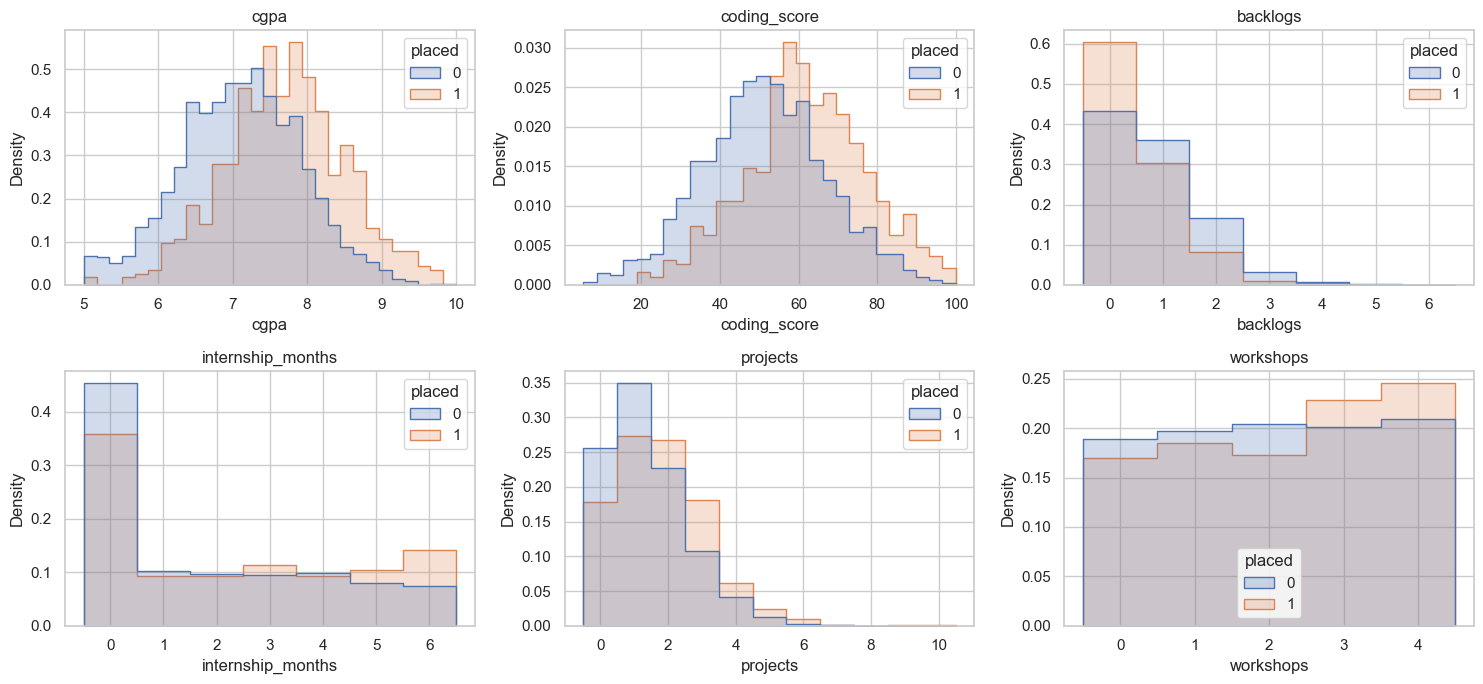

In [7]:
num_cols = ["cgpa", "coding_score", "backlogs", "internship_months", "projects", "workshops"]
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for ax, c in zip(axes.flat, num_cols):
    sns.histplot(data=df, x=c, hue="placed", stat="density", common_norm=False, element="step",
                 discrete=c not in ("cgpa", "coding_score"), ax=ax)
    ax.set_title(c)
plt.tight_layout()

### 1.3 Placement rate by feature

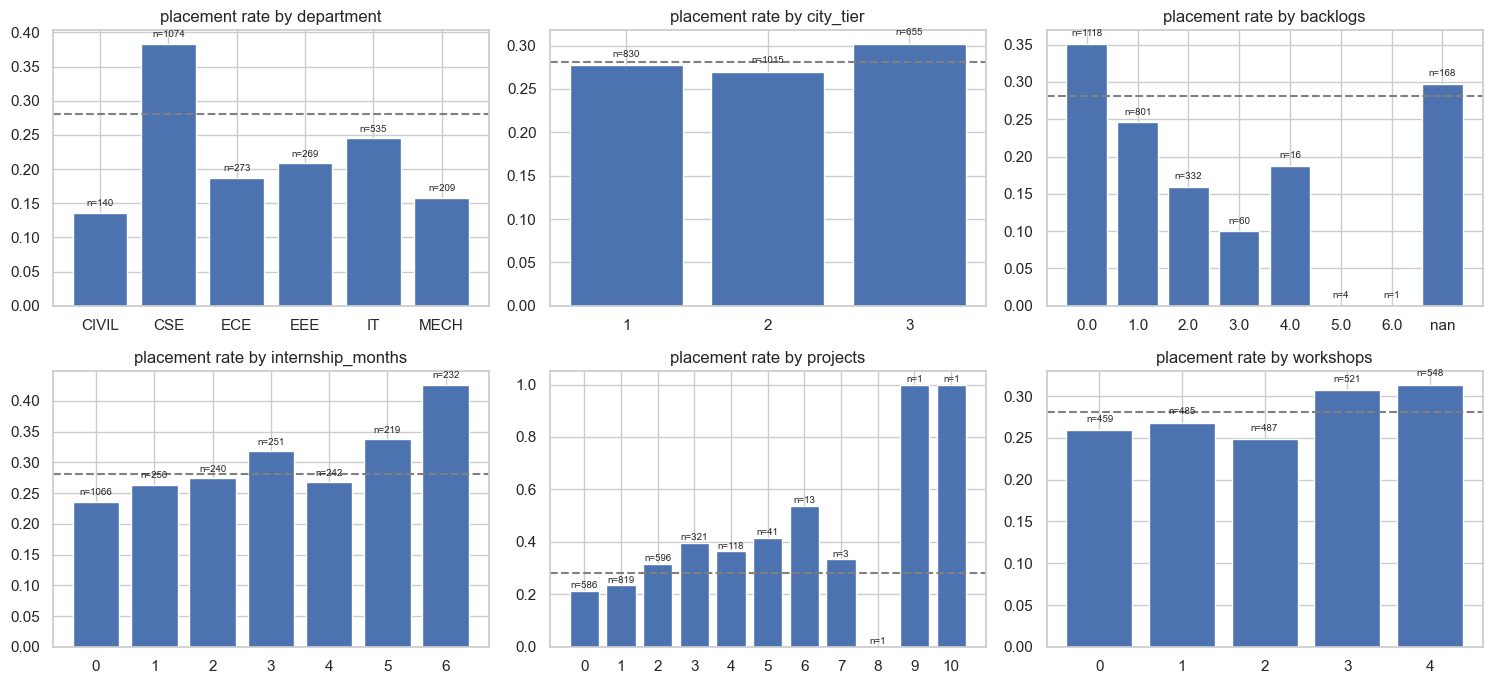

In [8]:
disc = ["department", "city_tier", "backlogs", "internship_months", "projects", "workshops"]
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for ax, c in zip(axes.flat, disc):
    g = df.groupby(c, dropna=False).placed.agg(["mean", "count"]).reset_index()
    g[c] = g[c].astype(str)
    ax.bar(g[c], g["mean"])
    for x, (m, n) in enumerate(zip(g["mean"], g["count"])):
        ax.text(x, m + 0.01, f"n={n}", ha="center", fontsize=7)
    ax.axhline(df.placed.mean(), ls="--", c="grey")
    ax.set_title(f"placement rate by {c}")
plt.tight_layout()

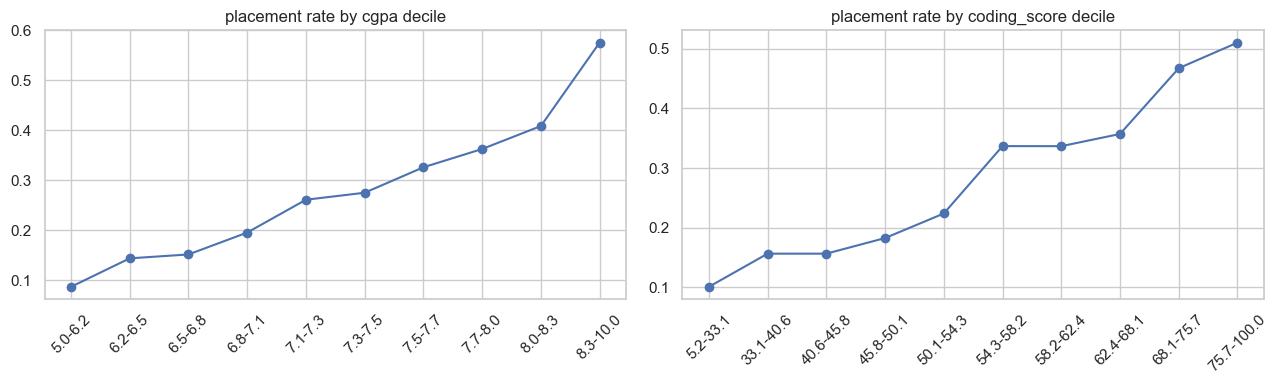

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, c in zip(axes, ["cgpa", "coding_score"]):
    bins = pd.qcut(df[c], 10)
    r = df.groupby(bins, observed=True).placed.mean()
    ax.plot(range(len(r)), r.values, marker="o")
    ax.set_xticks(range(len(r)), [f"{i.left:.1f}-{i.right:.1f}" for i in r.index], rotation=45)
    ax.set_title(f"placement rate by {c} decile")
plt.tight_layout()

In [10]:
# Does the department effect survive controlling for CGPA / coding score?
df.groupby("department")[["cgpa", "coding_score", "internship_months", "projects"]].mean().round(2).join(
    df.groupby("department").placed.mean().rename("placed_rate").round(3))

,cgpa,coding_score,internship_months,projects,placed_rate
department,,,,,
CIVIL,7.25,55.14,2.22,1.50,0.136
CSE,7.29,54.27,2.00,1.52,0.384
ECE,7.29,55.01,1.92,1.45,0.187
EEE,7.34,53.97,1.94,1.41,0.208
IT,7.20,53.47,1.90,1.52,0.245
MECH,7.32,55.36,1.96,1.65,0.158


**Feature findings**
- **CGPA** and **coding score** have the strongest effects, and both rise steadily: about 10% placed in the lowest decile versus about 50% or more in the highest.
- **Department** matters on its own. CSE is placed at 38%, CIVIL and MECH at about 14–16%. Average CGPA and coding score are similar across departments, so the gap is not just ability. Recruiters seem to prefer some branches.
- **Backlogs** reduce the chance of placement steadily (35% with none, 10% with three).
- **Internship months** and **projects** help a little, mostly at the top end (5–6 months, 3+ projects).
- **City tier** and **workshops** show almost no difference (27–31% across levels), so they will add little signal.

### 1.4 Missing values: random, or informative?

In [11]:
miss_cols = ["cgpa", "backlogs", "coding_score", "status_code"]
pd.DataFrame({c: df.groupby(df[c].isna()).placed.mean() for c in miss_cols}).T.rename(
    columns={False: "rate_when_present", True: "rate_when_missing"}).join(df[miss_cols].isna().sum().rename("n_missing")).round(3)

,rate_when_present,rate_when_missing,n_missing
cgpa,0.277,0.347,118
backlogs,0.280,0.298,168
coding_score,0.283,0.274,525
status_code,0.284,0.212,113


In [12]:
# Do missing values cluster together, or by department?
print(df[miss_cols].isna().astype(int).corr().round(2))
df.assign(**{f"{c}_missing": df[c].isna() for c in miss_cols}).groupby("department")[[f"{c}_missing" for c in miss_cols]].mean().round(3)

              cgpa  backlogs  coding_score  status_code
cgpa          1.00       0.0          0.01        -0.02
backlogs      0.00       1.0         -0.00         0.00
coding_score  0.01      -0.0          1.00         0.00
status_code  -0.02       0.0          0.00         1.00


,cgpa_missing,backlogs_missing,coding_score_missing,status_code_missing
department,,,,
CIVIL,0.043,0.093,0.200,0.071
CSE,0.041,0.068,0.214,0.046
ECE,0.048,0.073,0.198,0.040
EEE,0.052,0.045,0.223,0.052
IT,0.064,0.075,0.185,0.045
MECH,0.033,0.048,0.258,0.024


**Missing-value findings**
- Missing values in different columns are uncorrelated with each other and spread evenly across departments.
- Placement rates are about the same whether a value is present or missing (for example, coding score: 28.3% vs 27.4%). The small gap for `cgpa` (34.7% vs 27.7%) comes from only 118 rows and is within noise.
- So the values look **missing at random**. Median imputation is reasonable. Missing-value indicator columns are cheap to add and the model can ignore them if useless.

### 1.5 Correlations

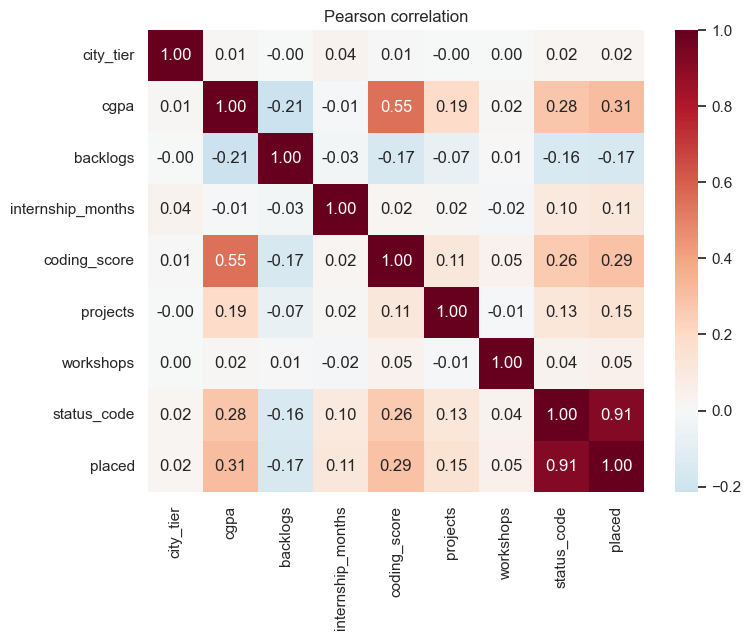

In [13]:
corr = df.drop(columns=["student_id", "department"]).corr()
plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0)
plt.title("Pearson correlation");

`cgpa` and `coding_score` are fairly correlated with each other (0.55), so they partly overlap. Every real feature has a modest correlation with `placed`, at most 0.31 (cgpa).
`status_code` correlates **0.91** with `placed`, which is far higher than everything else. The next section looks at it.

### 1.6 `status_code`: is it a leak?

In [14]:
pd.crosstab(df.status_code.fillna(-1).map({-1: "missing", 0: "0", 1: "1"}), df.placed, margins=True)

placed,0,1,All
status_code,,,
0,1654,33,1687
1,55,645,700
missing,89,24,113
All,1798,702,2500


In [15]:
from sklearn.metrics import f1_score, precision_score, recall_score
known = df.status_code.notna()
pred = df.loc[known, "status_code"].astype(int)
print("status_code used directly as the prediction (rows where it's known):")
print(f"  precision={precision_score(df.placed[known], pred):.3f}  "
      f"recall={recall_score(df.placed[known], pred):.3f}  F1={f1_score(df.placed[known], pred):.3f}")

status_code used directly as the prediction (rows where it's known):
  precision=0.921  recall=0.951  F1=0.936


In [16]:
# If status_code were an input (e.g. 'eligible'), it would depend on cgpa/backlogs in its own way.
# If it records the outcome, its groups should look exactly like the placed groups.
prof = pd.concat({
    "status_code=0": df[df.status_code == 0],
    "status_code=1": df[df.status_code == 1],
    "placed=0": df[df.placed == 0],
    "placed=1": df[df.placed == 1],
}, names=["group"]).groupby("group")[["cgpa", "coding_score", "backlogs", "internship_months", "projects"]].mean().round(2)
prof

,cgpa,coding_score,backlogs,internship_months,projects
group,,,,,
placed=0,7.11,51.30,0.83,1.82,1.39
placed=1,7.70,61.85,0.51,2.37,1.81
status_code=0,7.13,51.56,0.83,1.84,1.41
status_code=1,7.65,60.91,0.53,2.30,1.77


**`status_code` findings**
- When it is 1, 92% of students were placed. When it is 0, only 2% were. Used directly as the prediction, it gets **F1 ≈ 0.94**, which no real feature comes near.
- The students with `status_code = 1` look just like the students with `placed = 1` (same average CGPA, coding score and backlogs). The column behaves like a **copy of the outcome**, not like an input that explains it.
- The README calls it only "a field stored on the placement portal". Portal status fields such as *offer received*, *accepted* or *closed* are usually updated **after** the placement process. At the time we want to predict (a fresh list of registered students), that value would not exist yet.
- Conclusion: `status_code` is almost certainly **target leakage**. A model that uses it isn't predicting placement; it's reading a recorded outcome.

**What I do with it:** the main model **excludes** `status_code`. The scoring file is said to have the same columns, so I also train a second model that uses it, to show what it is worth. `predict.py` uses the leak-free model by default; the other one is available only behind an explicit flag.

### 1.7 EDA summary → modelling decisions
| Finding | Decision |
| --- | --- |
| 28% positive class, F1 metric | Tune the decision threshold with cross-validation; don't use 0.5 |
| Missing values look random, and any cell in the scoring file may be empty | Median/most-frequent imputation inside the pipeline, plus missing-value indicators, for **every** column |
| CGPA, coding score, backlogs and department carry the signal; trends are mostly smooth | A linear model should do well; compare it with tree ensembles |
| `city_tier` and `workshops` show little signal | Keep them (cheap), and check whether dropping them changes the CV score |
| `status_code` is effectively the label | Leave it out of the main model; train a separate "with status_code" model only for comparison |
| `student_id` is just an identifier | Not used as a feature |

## 2. Modelling
### 2.1 Setup
`predict.py` defines `prepare()`, the one function that cleans raw rows for **both** training and scoring. It adds any missing column as empty, turns unreadable numbers into NaN, and normalises department names. That way training and scoring prepare data exactly the same way.

In [17]:
import warnings
warnings.filterwarnings("ignore")
import joblib, sklearn
from sklearn.base import clone
from sklearn.compose import make_column_transformer
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, confusion_matrix
from sklearn.model_selection import RepeatedStratifiedKFold, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, PolynomialFeatures, SplineTransformer, StandardScaler

from predict import prepare

X_all = prepare(df)
y = df.placed.values

BASE = ["city_tier", "cgpa", "backlogs", "internship_months", "coding_score", "projects", "workshops"]
WITH_STATUS = BASE + ["status_code"]

In [18]:
dept_enc = lambda: make_pipeline(SimpleImputer(strategy="most_frequent"),
                                 OneHotEncoder(handle_unknown="ignore", sparse_output=False))

def logreg(num, C=1.0, spline=False, interactions=False, department=True):
    num_steps = ([SimpleImputer(strategy="median"), SplineTransformer(n_knots=4)] if spline
                 else [SimpleImputer(strategy="median", add_indicator=True), StandardScaler()])
    blocks = [(make_pipeline(*num_steps), num)] + ([(dept_enc(), ["department"])] if department else [])
    steps = [make_column_transformer(*blocks)]
    if interactions:
        steps += [PolynomialFeatures(2, interaction_only=True, include_bias=False), StandardScaler()]
    return make_pipeline(*steps, LogisticRegression(C=C, max_iter=5000))

def trees(num, model):
    # Tree models handle NaN natively (HGB) or via imputation (RF)
    numeric = "passthrough" if isinstance(model, HistGradientBoostingClassifier) else SimpleImputer(strategy="median", add_indicator=True)
    return make_pipeline(make_column_transformer((numeric, num), (dept_enc(), ["department"])), model)

### 2.2 Evaluation protocol
- **Repeated stratified 5-fold CV (3 repeats, 15 fits)**. One 5-fold split is noisy on 2,500 rows, and models differ by only a few hundredths of F1.
- Each repeat gives a full set of out-of-fold probabilities. I sweep the threshold, average the F1 curve over the repeats, and report the **best average F1 and its threshold**. The metric is F1, so the threshold is part of the model.
- Baseline: predicting "placed" for everyone gives F1 = 2·0.28/1.28 ≈ **0.44**. Any useful model has to beat that.

In [19]:
THRESHOLDS = np.round(np.arange(0.10, 0.80, 0.01), 2)

def oof_probs(model, features, X=X_all, y=y, n_repeats=3, seed=42):
    cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=n_repeats, random_state=seed)
    oof = np.zeros((n_repeats, len(y)))
    for i, (tr, te) in enumerate(cv.split(X, y)):
        m = clone(model).fit(X.iloc[tr], y[tr])
        oof[i // 5, te] = m.predict_proba(X.iloc[te])[:, 1]
    return oof

def f1_curve(oof, y=y):
    # F1 at each threshold, averaged over repeats (vectorised)
    curves = []
    for p in oof:
        pred = p[None, :] >= THRESHOLDS[:, None]
        tp = (pred & (y == 1)).sum(1); fp = (pred & (y == 0)).sum(1); fn = ((~pred) & (y == 1)).sum(1)
        curves.append(2 * tp / np.maximum(2 * tp + fp + fn, 1))
    return np.mean(curves, axis=0)

def evaluate(model, features):
    oof = oof_probs(model, features)
    curve = f1_curve(oof)
    best = curve.argmax()
    return {"cv_auc": np.mean([roc_auc_score(y, p) for p in oof]),
            "f1_at_0.5": curve[np.where(THRESHOLDS == 0.5)[0][0]],
            "best_f1": curve[best], "threshold": THRESHOLDS[best]}, curve

In [20]:
NO_TIER_WS = [c for c in BASE if c not in ("city_tier", "workshops")]
candidates = {
    "logreg C=1":                        (logreg(BASE, C=1.0), BASE),
    "logreg C=0.1":                      (logreg(BASE, C=0.1), BASE),
    "logreg C=0.03":                     (logreg(BASE, C=0.03), BASE),
    "logreg splines":                    (logreg(BASE, C=0.1, spline=True), BASE),
    "logreg pairwise interactions":      (logreg(BASE, C=0.05, interactions=True), BASE),
    "logreg w/o city_tier, workshops":   (logreg(NO_TIER_WS, C=1.0), NO_TIER_WS),
    "hist gradient boosting":            (trees(BASE, HistGradientBoostingClassifier(max_depth=2, learning_rate=0.03, max_iter=300, min_samples_leaf=40, random_state=0)), BASE),
    "random forest":                     (trees(BASE, RandomForestClassifier(400, min_samples_leaf=10, random_state=0, n_jobs=-1)), BASE),
    "[status_code] logreg C=1":          (logreg(WITH_STATUS, C=1.0), WITH_STATUS),
    "[status_code] hist grad boosting":  (trees(WITH_STATUS, HistGradientBoostingClassifier(max_depth=2, learning_rate=0.05, max_iter=200, min_samples_leaf=40, random_state=0)), WITH_STATUS),
}
results, curves = {}, {}
for name, (model, feats) in candidates.items():
    results[name], curves[name] = evaluate(model, feats)
pd.DataFrame(results).T.round(3)

,cv_auc,f1_at_0.5,best_f1,threshold
logreg C=1,0.766,0.448,0.566,0.25
logreg C=0.1,0.766,0.430,0.562,0.26
logreg C=0.03,0.764,0.402,0.560,0.28
logreg splines,0.766,0.381,0.569,0.28
logreg pairwise interactions,0.743,0.447,0.545,0.24
"logreg w/o city_tier, workshops",0.766,0.445,0.563,0.31
hist gradient boosting,0.755,0.424,0.555,0.29
random forest,0.754,0.385,0.566,0.31
[status_code] logreg C=1,0.975,0.922,0.924,0.56
[status_code] hist grad boosting,0.972,0.918,0.920,0.58


**Model comparison**
- Every model **without** `status_code` scores CV F1 between 0.55 and 0.57. The differences are about the size of the noise between CV repeats. Splines, interactions, gradient boosting and random forests add nothing over plain logistic regression, which matches the smooth, roughly additive trends from the EDA.
- Dropping `city_tier` and `workshops` changes almost nothing, as the EDA predicted. I keep them, because removing them gains nothing and they cost nothing.
- **Chosen model: logistic regression (C=1) with a tuned threshold.** It is as accurate as the alternatives, is the simplest, its coefficients can be read directly (section 2.5), and it is least likely to overfit a fresh list.
- With `status_code`, every model reaches about 0.92. That jump comes almost entirely from the leaked column (section 1.6).
- Tuning the threshold matters: at the default 0.5 cut-off the leak-free model scores much lower F1, because only about 28% of students are positive.

### 2.3 Threshold choice

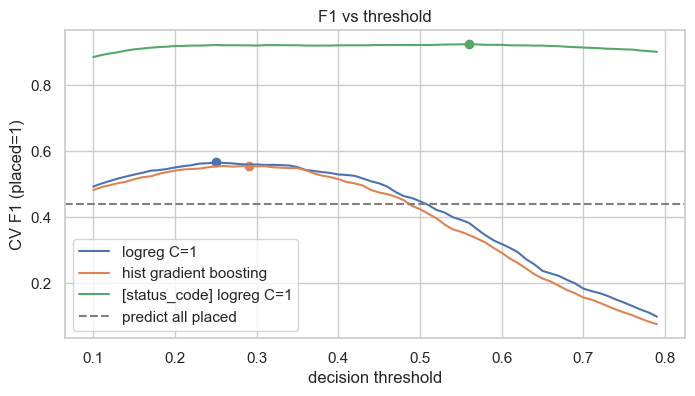

In [21]:
fig, ax = plt.subplots(figsize=(8, 4))
for name in ["logreg C=1", "hist gradient boosting", "[status_code] logreg C=1"]:
    ax.plot(THRESHOLDS, curves[name], label=name)
    ax.scatter(results[name]["threshold"], results[name]["best_f1"])
ax.axhline(2 * y.mean() / (1 + y.mean()), ls="--", c="grey", label="predict all placed")
ax.set_xlabel("decision threshold"); ax.set_ylabel("CV F1 (placed=1)"); ax.legend(); ax.set_title("F1 vs threshold");

The leak-free F1 curve is flat near its peak: anywhere between about 0.20 and 0.30, F1 stays within about 0.015 of the best value, so the exact threshold isn't critical. The chosen value comes from CV out-of-fold predictions, never from the rows the final model was fitted on.

### 2.4 Holdout check
As a final honesty check, I set aside 20% of the data. On the remaining 80% I repeat the whole procedure (CV to pick the threshold, then fit), and then score the untouched 20% once.

In [22]:
idx_tr, idx_te = train_test_split(np.arange(len(y)), test_size=0.2, stratify=y, random_state=7)
rows = {}
for name, feats in [("logreg C=1", BASE), ("[status_code] logreg C=1", WITH_STATUS)]:
    model = candidates[name][0]
    Xtr, ytr = X_all.iloc[idx_tr], y[idx_tr]
    t = THRESHOLDS[f1_curve(oof_probs(model, feats, Xtr, ytr), ytr).argmax()]
    fitted = clone(model).fit(Xtr, ytr)
    pred = (fitted.predict_proba(X_all.iloc[idx_te])[:, 1] >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y[idx_te], pred).ravel()
    rows[name] = {"threshold": t, "precision": tp / (tp + fp), "recall": tp / (tp + fn),
                  "f1": 2 * tp / (2 * tp + fp + fn), "tp": tp, "fp": fp, "fn": fn, "tn": tn}
pd.DataFrame(rows).T.round(3)

,threshold,precision,recall,f1,tp,fp,fn,tn
logreg C=1,0.26,0.467,0.757,0.578,106.0,121.0,34.0,239.0
[status_code] logreg C=1,0.50,0.893,0.957,0.924,134.0,16.0,6.0,344.0


The holdout F1 is close to the CV estimate, so that estimate is a fair guess of performance on the separate list. The leak-free model trades precision for recall: it flags more students than are actually placed to catch most real placements, which is the trade-off F1 rewards when the positive class is about 28% of students.

### 2.5 What the model learned

,coef
department_CIVIL,-0.611
department_MECH,-0.459
backlogs,-0.293
department_ECE,-0.154
department_EEE,-0.043
missingindicator_backlogs,0.038
missingindicator_coding_score,0.040
city_tier,0.040
workshops,0.082
missingindicator_cgpa,0.096


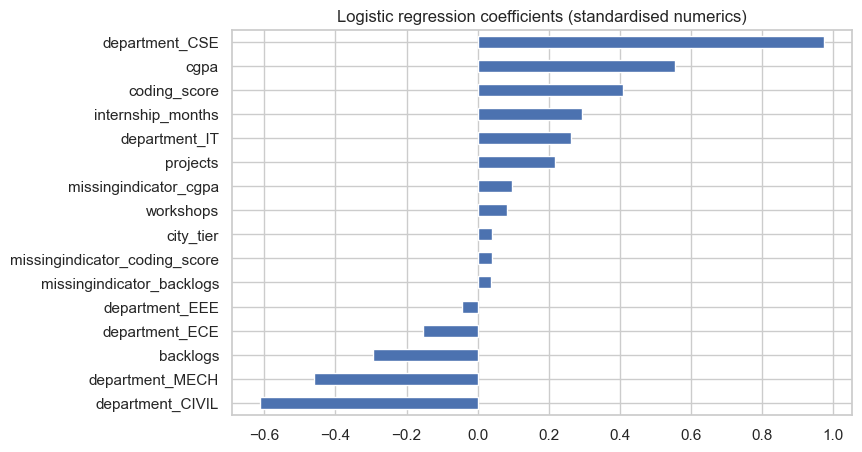

In [23]:
final_base = clone(candidates["logreg C=1"][0]).fit(X_all, y)
names = [n.split("__", 1)[1] for n in final_base[:-1].get_feature_names_out()]
coef = pd.Series(final_base[-1].coef_[0], index=names).sort_values()
plt.figure(figsize=(8, 5)); coef.plot.barh(); plt.title("Logistic regression coefficients (standardised numerics)");
coef.round(3).to_frame("coef")

The coefficients agree with the EDA: CGPA and coding score push placement up most, backlogs push it down, and CSE (then IT) has a clear department advantage over CIVIL and MECH. Internships and projects add a little. City tier, workshops and the missing-value indicators are close to zero.

### 2.6 Stress test: what does the `status_code` model do without the leak?
Section 1.6 argued that `status_code` is recorded *after* the outcome. If that's right, a genuinely new list of registered students would have it **empty** (no outcome yet) or stuck at its **default 0** (not yet updated). I train both models on the 80% split from 2.4 and score the untouched 20% three ways: as recorded, with `status_code` blanked, and with it set to 0.

,as recorded,status_code blank,status_code = 0
logreg C=1,0.578,0.578,0.578
[status_code] logreg C=1,0.924,0.337,0.056


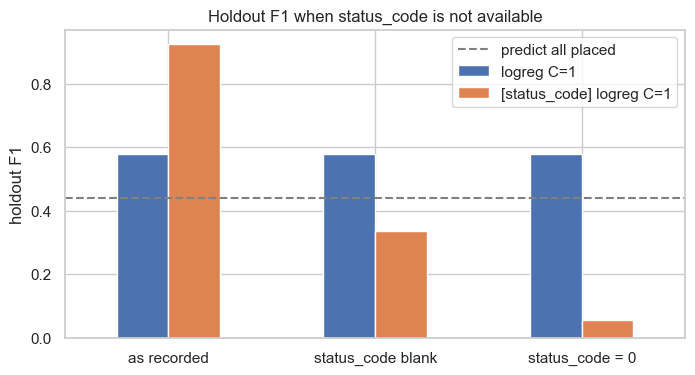

In [24]:
Xtr, ytr = X_all.iloc[idx_tr], y[idx_tr]
Xte, yte = X_all.iloc[idx_te], y[idx_te]
scenarios = {
    "as recorded": Xte,
    "status_code blank": Xte.assign(status_code=np.nan),
    "status_code = 0": Xte.assign(status_code=0.0),
}
stress = {}
for name in ["logreg C=1", "[status_code] logreg C=1"]:
    fitted = clone(candidates[name][0]).fit(Xtr, ytr)
    t = rows[name]["threshold"]
    stress[name] = {s: f1_score(yte, fitted.predict_proba(Xs)[:, 1] >= t) for s, Xs in scenarios.items()}
stress = pd.DataFrame(stress).T
ax = stress.T.plot.bar(figsize=(8, 4), rot=0)
ax.axhline(2 * y.mean() / (1 + y.mean()), ls="--", c="grey", label="predict all placed")
ax.set_ylabel("holdout F1"); ax.legend(); ax.set_title("Holdout F1 when status_code is not available")
stress.round(3)

The training data also contains a small **natural experiment**: 113 students whose `status_code` is genuinely missing. Here is how each model scores on just those rows (out-of-fold predictions, so no row is scored by a model trained on it):

In [25]:
sc_missing = df.status_code.isna().values
natural = {}
for name in ["logreg C=1", "[status_code] logreg C=1"]:
    p = oof_probs(candidates[name][0], None, n_repeats=1)[0] >= results[name]["threshold"]
    natural[name] = {"F1, status_code present": f1_score(y[~sc_missing], p[~sc_missing]),
                     f"F1, status_code missing (n={sc_missing.sum()})": f1_score(y[sc_missing], p[sc_missing])}
pd.DataFrame(natural).T.round(3)

,"F1, status_code present","F1, status_code missing (n=113)"
logreg C=1,0.561,0.592
[status_code] logreg C=1,0.938,0.267


**Stress-test findings**
- The leak-free model scores the **same 0.578 in every scenario**, because it never relied on `status_code`.
- The `status_code` model goes from **0.92 to 0.34** when the field is blank and **0.06** when it is 0. Both are **worse than labelling every student "placed"** (0.44). It has learned "copy `status_code`", not "predict placement".
- The real data agrees. On the 113 students whose `status_code` really is missing, the `status_code` model falls to F1 0.27 while the leak-free model scores 0.59.
- So the 0.92 is only possible when the outcome is already recorded, which is exactly when no prediction is needed. **That is why `model.joblib` is the default.**

### 2.7 How certain is the F1 estimate?
A single number like "0.566" hides how much F1 can move on a list of a few hundred students. Using the leak-free model's out-of-fold predictions (each student scored by a model that never saw them), I check three things:
1. **List size:** the F1 range when scoring lists of different sizes (bootstrap, 2,000 resamples).
2. **Threshold stability:** how much the "best" threshold moves between resamples, and what using a fixed 0.25 costs.
3. **Placement rate:** the separate list may not have exactly 28% placed. How does a fixed threshold cope if the rate is higher or lower?

In [26]:
main = candidates["logreg C=1"][0]
t0 = results["logreg C=1"]["threshold"]
oof_main = oof_probs(main, None, n_repeats=1)[0]
rng = np.random.default_rng(0)

def fast_f1(yv, pred):
    tp = (pred & (yv == 1)).sum(-1); fp = (pred & (yv == 0)).sum(-1); fn = (~pred & (yv == 1)).sum(-1)
    return 2 * tp / np.maximum(2 * tp + fp + fn, 1)

ci = {}
for n in [250, 500, 1000, 2500]:
    idx = rng.integers(0, len(y), size=(2000, n))
    f = fast_f1(y[idx], oof_main[idx] >= t0)
    ci[f"list of {n}"] = {"median F1": np.median(f), "2.5%": np.percentile(f, 2.5), "97.5%": np.percentile(f, 97.5)}
pd.DataFrame(ci).T.round(3)

,median F1,2.5%,97.5%
list of 250,0.563,0.473,0.643
list of 500,0.561,0.500,0.617
list of 1000,0.562,0.518,0.602
list of 2500,0.561,0.534,0.588


In [27]:
# Re-pick the best threshold on each bootstrap resample of 2,500
best_t, regret = [], []
for _ in range(500):
    idx = rng.integers(0, len(y), len(y))
    curve = fast_f1(y[idx][None, :], oof_main[idx][None, :] >= THRESHOLDS[:, None])
    best_t.append(THRESHOLDS[curve.argmax()])
    regret.append(curve.max() - curve[np.where(THRESHOLDS == t0)[0][0]])
best_t = np.array(best_t)
print(f"best threshold across resamples: median {np.median(best_t):.2f}, 90% range {np.percentile(best_t, 5):.2f}-{np.percentile(best_t, 95):.2f}")
print(f"F1 lost by fixing threshold at {t0:.2f} instead of the per-resample best: median {np.median(regret):.3f}, 95th pct {np.percentile(regret, 95):.3f}")

best threshold across resamples: median 0.26, 90% range 0.23-0.35
F1 lost by fixing threshold at 0.25 instead of the per-resample best: median 0.003, 95th pct 0.013


In [28]:
# Simulate lists with a different placement rate by resampling positives/negatives
pos, neg = np.where(y == 1)[0], np.where(y == 0)[0]
shift = {}
for rate in [0.15, 0.20, 0.28, 0.35, 0.45]:
    n_pos = int(2000 * rate)
    fixed, oracle, oracle_t = [], [], []
    for _ in range(200):
        idx = np.concatenate([rng.choice(pos, n_pos), rng.choice(neg, 2000 - n_pos)])
        curve = fast_f1(y[idx][None, :], oof_main[idx][None, :] >= THRESHOLDS[:, None])
        fixed.append(curve[np.where(THRESHOLDS == t0)[0][0]]); oracle.append(curve.max()); oracle_t.append(THRESHOLDS[curve.argmax()])
    shift[f"{rate:.0%} placed"] = {f"F1 @ {t0:.2f}": np.mean(fixed), "best possible F1": np.mean(oracle),
                                   "best threshold": np.median(oracle_t), "all-placed baseline": 2 * rate / (1 + rate)}
pd.DataFrame(shift).T.round(3)

,F1 @ 0.25,best possible F1,best threshold,all-placed baseline
15% placed,0.396,0.432,0.415,0.261
20% placed,0.471,0.490,0.350,0.333
28% placed,0.562,0.567,0.260,0.438
35% placed,0.619,0.623,0.230,0.519
45% placed,0.685,0.695,0.220,0.621


**Uncertainty findings**
- **Expect roughly 0.50–0.62 on a list of 500**: about ±0.06 from sampling luck alone, and ±0.03 even on a list of 2,500. Differences of 0.01 between models (section 2.2) are well inside this range. That is another reason not to swap the simple model for a more complex one that scores fractionally higher.
- **The threshold is stable.** The best threshold stays between 0.23 and 0.35 across resamples, and keeping it fixed at 0.25 costs a median of **0.003 F1**.
- **The placement rate matters more than the model.** The same model scores about 0.40 if only 15% of the list is placed and about 0.69 if 45% are. That is simply how F1 behaves, not a flaw in the model. A fixed 0.25 threshold stays within **0.04** of the best possible F1 at every rate tested, and always beats the "all placed" baseline. Without knowing the rate of the separate list, the fixed threshold is the safe choice.

### 2.8 Error analysis: who does the model get wrong?
I label every student as a true positive, false positive, false negative or true negative, using the out-of-fold predictions at threshold 0.25, and compare the groups.

In [29]:
err = df.assign(p=oof_main, pred=(oof_main >= t0).astype(int))
err["outcome"] = np.select(
    [(err.pred == 1) & (err.placed == 1), (err.pred == 1) & (err.placed == 0), (err.pred == 0) & (err.placed == 1)],
    ["TP: placed, caught", "FP: flagged, not placed", "FN: placed, missed"], "TN: not placed, not flagged")
cols = ["cgpa", "coding_score", "backlogs", "internship_months", "projects", "p"]
err.groupby("outcome")[cols].mean().round(2).join(err.outcome.value_counts().rename("n"))

,cgpa,coding_score,backlogs,internship_months,projects,p,n
outcome,,,,,,,
"FN: placed, missed",7.01,50.31,0.77,1.63,1.30,0.16,179
"FP: flagged, not placed",7.68,61.25,0.46,2.35,1.73,0.42,637
"TN: not placed, not flagged",6.81,46.08,1.04,1.53,1.21,0.12,1161
"TP: placed, caught",7.95,65.72,0.42,2.62,1.99,0.51,523


In [30]:
by_dept = err.groupby("department").apply(lambda g: pd.Series({
    "n": len(g), "placed_rate": g.placed.mean(), "flagged_rate": g.pred.mean(),
    "precision": g.placed[g.pred == 1].mean(),
    "recall": g.pred[g.placed == 1].mean(),
    "F1": f1_score(g.placed, g.pred)}), include_groups=False)
by_dept.round(3).sort_values("placed_rate", ascending=False)

,n,placed_rate,flagged_rate,precision,recall,F1
department,,,,,,
CSE,1074.0,0.384,0.689,0.480,0.862,0.616
IT,535.0,0.245,0.407,0.422,0.702,0.527
EEE,269.0,0.208,0.297,0.412,0.589,0.485
ECE,273.0,0.187,0.216,0.322,0.373,0.345
MECH,209.0,0.158,0.201,0.357,0.455,0.400
CIVIL,140.0,0.136,0.150,0.429,0.474,0.450


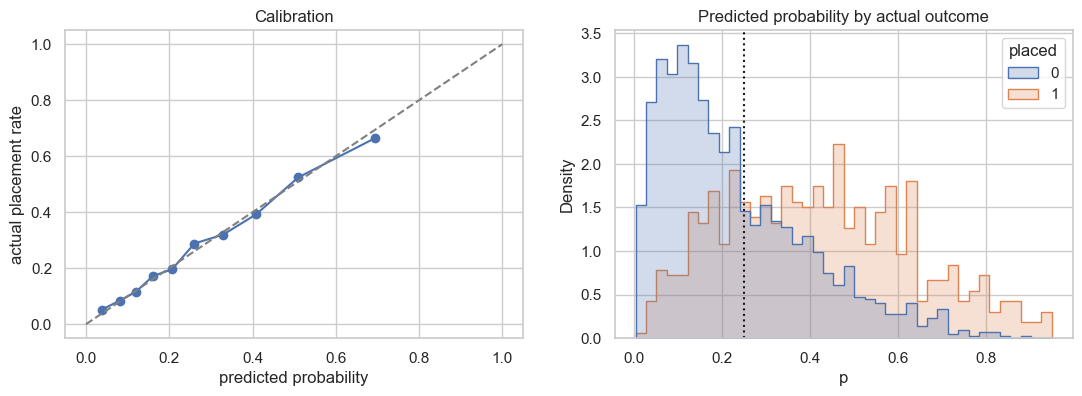

In [31]:
# Are the probabilities trustworthy? (reliability curve on out-of-fold predictions)
from sklearn.calibration import calibration_curve
frac, mean_p = calibration_curve(y, oof_main, n_bins=10, strategy="quantile")
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(mean_p, frac, marker="o"); axes[0].plot([0, 1], [0, 1], ls="--", c="grey")
axes[0].set_xlabel("predicted probability"); axes[0].set_ylabel("actual placement rate"); axes[0].set_title("Calibration")
sns.histplot(data=err, x="p", hue="placed", bins=40, element="step", stat="density", common_norm=False, ax=axes[1])
axes[1].axvline(t0, c="k", ls=":"); axes[1].set_title("Predicted probability by actual outcome");

**Error-analysis findings**
- **Missed placements (FN, 179) look like ordinary unplaced students.** Their average CGPA (7.0), coding score (50) and backlogs (0.77) are close to the true negatives and far from the students the model catches (7.9, 66, 0.42). Something the data doesn't record got them placed: interview performance, a referral, a recruiter's specific need. No reweighting of these features will find them.
- **False alarms (FP, 637) look like strong candidates** (CGPA 7.7, coding 61), close to the true positives. They had the profile but no offer. Again, the cause is outside this data.
- **Errors are not spread evenly across departments.** In CSE the model flags 69% of students and catches 86% of those placed. In ECE it catches only 37%, because the department penalty keeps most ECE students below the threshold. F1 ranges from 0.35 (ECE) to 0.62 (CSE). The model is reproducing the existing department gap, which matters for how it is used (next section).
- **The probabilities are well calibrated.** A predicted 0.4 really means about 40% of such students get placed. So the scores can be used directly as a "chance of placement", not just as a 0/1 label.
- The two groups overlap heavily between 0.15 and 0.5 (right chart). That overlap is where the F1 ceiling comes from: with these features, many placed and unplaced students look identical.

### 2.9 Fairness and how the placement cell would use this
Two features describe *who the student is* rather than *what they've done*:
- **`city_tier`** may stand in for family background or income.
- **`department`** reflects which branches recruiters come for, which the student can't change after admission.

If the cell uses predictions to decide who gets extra help, it matters whether these features drive them. I compare three versions: the current model, one without `city_tier`, and a "merit only" model with neither.

In [32]:
NO_TIER = [c for c in BASE if c != "city_tier"]
fair_variants = {
    "current (all features)": logreg(BASE),
    "without city_tier": logreg(NO_TIER),
    "merit only (no city_tier, no department)": logreg(NO_TIER, department=False),
}
fair_rows, fair_recall = {}, {}
for name, model in fair_variants.items():
    res, _ = evaluate(model, None)
    p = oof_probs(model, None, n_repeats=1)[0] >= res["threshold"]
    recall = pd.Series(p[y == 1]).groupby(df.department[y == 1].values).mean()
    fair_rows[name] = {**res, "recall spread across depts": recall.max() - recall.min()}
    fair_recall[name] = recall
display(pd.DataFrame(fair_rows).T.round(3))
pd.DataFrame(fair_recall).round(3).rename_axis("recall of placed students, by department")

,cv_auc,f1_at_0.5,best_f1,threshold,recall spread across depts
current (all features),0.766,0.448,0.566,0.25,0.489
without city_tier,0.766,0.448,0.564,0.25,0.489
"merit only (no city_tier, no department)",0.730,0.366,0.533,0.27,0.234


,current (all features),without city_tier,"merit only (no city_tier, no department)"
"recall of placed students, by department",,,
CIVIL,0.474,0.474,0.842
CSE,0.862,0.862,0.672
ECE,0.373,0.373,0.608
EEE,0.589,0.571,0.804
IT,0.702,0.718,0.748
MECH,0.455,0.485,0.788


**Using the scores to target support.** The probabilities are calibrated (2.8), so the cell can rank students instead of using a single cut-off. If it can coach only a fixed number of students, how many of those it picks would otherwise go unplaced?

In [33]:
order = np.argsort(oof_main)            # lowest predicted chance first
unplaced_rate = 1 - y.mean()
lift = {}
for share in [0.1, 0.2, 0.3, 0.5]:
    k = int(len(y) * share)
    picked = order[:k]
    lift[f"lowest {share:.0%} ({k} students)"] = {
        "share actually unplaced": 1 - y[picked].mean(),
        "random pick": unplaced_rate,
        "unplaced students reached": (y[picked] == 0).sum() / (y == 0).sum(),
    }
pd.DataFrame(lift).T.round(3)

,share actually unplaced,random pick,unplaced students reached
lowest 10% (250 students),0.948,0.719,0.132
lowest 20% (500 students),0.932,0.719,0.259
lowest 30% (750 students),0.916,0.719,0.382
lowest 50% (1250 students),0.876,0.719,0.609


**Fairness findings and decisions**
- **`city_tier` is dropped from the final model.** Removing it changes CV F1 from 0.566 to 0.564, well inside the noise from 2.7, and it removes a possible proxy for family background. When a feature adds nothing, there's no reason to keep one that could encode privilege.
- **`department` is kept, but this should be stated openly.** Removing it lowers CV F1 by about 0.03 and AUC by about 0.04, because recruiters really do prefer some branches. The cost is uneven error rates: the current model catches 86% of placed CSE students but only 37% of placed ECE students. The merit-only model halves that gap (recall spread 0.49 → 0.23).
  - The task here is to *predict* placement, so department stays.
  - For *allocating help*, the cell should compare students **within** a department or use the merit-only scores, so ECE or CIVIL students are not written off because of their branch.
- **As a targeting tool the model works well.** Of the 20% of students it rates least likely to be placed, 93% are in fact unplaced, against 72% for a random pick. Coaching those 500 students would reach about a quarter of everyone who ends up unplaced.

### 2.10 Train and save the final models
Both models are fitted on **all** 2,500 rows, using thresholds picked by cross-validation (sections 2.2 and 2.9).
- `model.joblib`: **default**. Logistic regression without `status_code` or `city_tier` (2.9).
- `model_with_status_code.joblib`: used only with `python predict.py --use-status-code`, for comparison.

The recipe lives in `train.py`, so `python train.py` rebuilds exactly the same files without the notebook. The check below confirms that `train.py` reproduces the threshold and CV F1 found in this notebook.

In [34]:
import train
final_specs = [
    ("model.joblib", train.DEFAULT_NUMERIC, NO_TIER, fair_rows["without city_tier"]),
    ("model_with_status_code.joblib", train.STATUS_NUMERIC, WITH_STATUS, results["[status_code] logreg C=1"]),
]
for fname, numeric, notebook_feats, res in final_specs:
    assert numeric == notebook_feats
    bundle = train.train_bundle(numeric, X_all, y)
    assert bundle["threshold"] == res["threshold"] and abs(bundle["cv_f1"] - res["best_f1"]) < 1e-12, "train.py disagrees with notebook"
    joblib.dump(bundle, fname)
    print(f"{fname}: features={bundle['features']}  threshold={bundle['threshold']:.2f}  CV F1={bundle['cv_f1']:.3f}")

model.joblib: features=['cgpa', 'backlogs', 'internship_months', 'coding_score', 'projects', 'workshops', 'department']  threshold=0.25  CV F1=0.564


model_with_status_code.joblib: features=['city_tier', 'cgpa', 'backlogs', 'internship_months', 'coding_score', 'projects', 'workshops', 'status_code', 'department']  threshold=0.56  CV F1=0.924


### 2.11 Smoke test of `predict.py`
The scoring file "can have empty cells". This test runs `predict.py` on rows that are blank, entirely empty, have a missing column, an unseen department and junk values, and checks the output format.

In [35]:
import subprocess, sys, tempfile, os
messy = df.drop(columns="placed").sample(200, random_state=1).reset_index(drop=True)
rng = np.random.default_rng(0)
for c in ["department", "city_tier", "cgpa", "backlogs", "internship_months", "coding_score", "projects", "status_code"]:
    messy.loc[rng.random(len(messy)) < 0.15, c] = np.nan             # random empty cells in every column
messy = messy.drop(columns="workshops")                               # a whole column missing
messy["department"] = messy["department"].astype(object)
messy.loc[0, "department"] = "AI&DS"                                  # department never seen in training
messy.loc[1, "department"] = " cse "                                  # messy formatting
messy["cgpa"] = messy["cgpa"].astype(object); messy.loc[2, "cgpa"] = "n/a"   # junk value
messy.loc[3, messy.columns[1:]] = np.nan                              # a row with nothing but an id

with tempfile.TemporaryDirectory() as tmp:
    src, dst = os.path.join(tmp, "in.csv"), os.path.join(tmp, "out.csv")
    messy.to_csv(src, index=False)
    for extra in [[], ["--use-status-code"]]:
        r = subprocess.run([sys.executable, "predict.py", "--input", src, "--output", dst, *extra], capture_output=True, text=True)
        print(r.stdout.strip() or r.stderr)
        out = pd.read_csv(dst, dtype={"student_id": str})
        assert list(out.columns) == ["student_id", "placed"]
        assert out.student_id.tolist() == messy.student_id.tolist()
        assert set(out.placed.unique()) <= {0, 1}
print("all checks passed")

model.joblib: wrote 200 rows to C:\Users\prano\AppData\Local\Temp\tmpxcc0qp64\out.csv (114 predicted placed, threshold 0.25)


model_with_status_code.joblib: wrote 200 rows to C:\Users\prano\AppData\Local\Temp\tmpxcc0qp64\out.csv (53 predicted placed, threshold 0.56)
all checks passed


## 3. Summary
- **Data checks:** missing values, ranges, duplicates, class balance, how each feature relates to placement, whether missing values carry signal, and leakage.
- **Features used (default model):** department, CGPA, backlogs, internship months, coding score, projects, workshops, and missing-value indicators. `student_id` is an identifier only.
- **Excluded: `status_code`.** It reproduces the label (F1 ≈ 0.94 on its own, and the same student profile as `placed`), and it is almost certainly written after the outcome. The stress test (2.6) shows the `status_code` model collapsing to F1 0.06–0.34 when the field isn't filled in yet, which is worse than predicting "placed" for everyone.
- **Excluded: `city_tier`.** It adds nothing (−0.002 F1) and may stand in for family background (2.9).
- **Model:** median/most-frequent imputation with missing-value indicators, standardisation, one-hot department, logistic regression, and a decision threshold (0.25) tuned for F1 with repeated CV. More complex models were no better. The probabilities are well calibrated.
- **Expected F1 on the new list:** about 0.56, likely between 0.50 and 0.62 on a list of 500 (2.7), against 0.44 for predicting everyone as placed. If the scoring file carries the same leaked `status_code`, `--use-status-code` gives about 0.92, but that model fails as soon as the field isn't already filled in.
- **Limitations:** most of the variation in placement is not explained by these features (AUC about 0.77). Missed placements look like ordinary students (2.8), so whatever placed them (interviews, referrals, recruiter needs) is not in the data. The model also reproduces the department gap; for allocating support, compare students within a department (2.9).